# Dataset B RQ2 — GSV and Shapley–Lorenz results

This notebook is a **read-only visualization layer** for the Task C-validated production run `rq2_cpu_production_20261009_01`. It loads saved result tables only: no model loading, coalition construction, inference, fitting, GSV/SL recomputation, or bootstrap recomputation occurs here.

The reported agreement and stability statistics are descriptive. They do not establish ground-truth explanation quality, causality, creditworthiness, default risk, or legal discrimination.

## 1. Setup and verified artifact loading

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

%matplotlib inline
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 120, "axes.titleweight": "bold"})

def find_project_root() -> Path:
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "config/dataset_b/rq2_protocol.yaml").is_file():
            return candidate
    raise FileNotFoundError("Run this notebook from inside the DAP391m_GR12 checkout.")

PROJECT_ROOT = find_project_root()
RUN_ID = "rq2_cpu_production_20261009_01"
RUN_ROOT = PROJECT_ROOT / "artifacts" / "dataset_b" / "rq2" / RUN_ID
MODEL_ORDER = ["lr", "rf", "xgboost", "plain_mlp", "realmlp", "tabmmini"]
MODEL_LABELS = {
    "lr": "LR", "rf": "RF", "xgboost": "XGBoost",
    "plain_mlp": "PlainMLP", "realmlp": "RealMLP", "tabmmini": "TabMmini",
}
METHOD_LABELS = {"gsv": "GSV", "shapley_lorenz": "Shapley–Lorenz"}
COLORS = {"gsv": "#2563EB", "shapley_lorenz": "#E76F51"}

if not RUN_ROOT.is_dir():
    raise FileNotFoundError(f"Verified RQ2 run not found: {RUN_ROOT}")

importance_frames, bootstrap_frames, status_rows = [], [], []
for model in MODEL_ORDER:
    model_root = RUN_ROOT / "models" / model
    status = json.loads((model_root / "status.json").read_text(encoding="utf-8"))
    status_rows.append(status)
    importance_frames.append(pd.read_csv(model_root / "importance.csv"))
    bootstrap_frames.append(pd.read_csv(model_root / "bootstrap.csv"))

importance = pd.concat(importance_frames, ignore_index=True)
bootstrap = pd.concat(bootstrap_frames, ignore_index=True)
statuses = pd.DataFrame(status_rows)
runtime = pd.read_csv(RUN_ROOT / "runtime.csv")
cross_model = pd.read_csv(RUN_ROOT / "cross_model_stability.csv")

assert statuses["model_key"].tolist() == MODEL_ORDER
assert statuses["status"].eq("PASS").all() and statuses["completed_chunks"].eq(10).all()
assert runtime["model_key"].tolist() == MODEL_ORDER and len(runtime) == 6
assert len(importance) == 144 and len(bootstrap) == 24 and len(cross_model) == 60
assert importance["result_status"].eq("PASS").all()

run_summary = statuses[["model_key", "model_run_id", "status", "completed_chunks"]].copy()
run_summary["model"] = run_summary["model_key"].map(MODEL_LABELS)
run_summary = run_summary[["model", "model_run_id", "status", "completed_chunks"]]
display(Markdown(f"**Loaded verified run:** `{RUN_ID}`  \n**Models:** 6/6 PASS · **Importance rows:** {len(importance)} · **Bootstrap rows:** {len(bootstrap)} · **Cross-model rows:** {len(cross_model)}"))
display(run_summary.style.hide(axis="index").format({"completed_chunks": "{:.0f}"}))

**Loaded verified run:** `rq2_cpu_production_20261009_01`  
**Models:** 6/6 PASS · **Importance rows:** 144 · **Bootstrap rows:** 24 · **Cross-model rows:** 60

model,model_run_id,status,completed_chunks
LR,lr_final_15f_20261002_01,PASS,10
RF,rf_final_15f_20261002_01,PASS,10
XGBoost,xgb_final_15f_20261003_01,PASS,10
PlainMLP,plain_mlp_final_15f_20261004_03,PASS,10
RealMLP,realmlp_final_15f_20261004_01,PASS,10
TabMmini,tabmmini_final_15f_20261004_01,PASS,10


## 2. Importance and ranking

Normalized importance is calculated separately within each explanation method. Top-3 includes all cutoff ties. The table below is descriptive and keeps model/method rankings separate.

In [2]:
ranking = importance[["model_key", "method", "player_key", "normalized_importance", "rank", "signed_summary"]].copy()
ranking["model"] = ranking["model_key"].map(MODEL_LABELS)
ranking["method_label"] = ranking["method"].map(METHOD_LABELS)
top_ranked = ranking.loc[ranking["rank"] <= 3].sort_values(["model_key", "method", "rank", "player_key"])
display(top_ranked[["model", "method_label", "rank", "player_key", "normalized_importance", "signed_summary"]].style.hide(axis="index").format({"rank": "{:.1f}", "normalized_importance": "{:.4f}", "signed_summary": "{:+.4f}"}))

model,method_label,rank,player_key,normalized_importance,signed_summary
LR,GSV,1.0,debt_to_income_ratio,0.3106,-0.0059
LR,GSV,2.0,loan_purpose,0.2378,+0.0210
LR,GSV,3.0,loan_to_value_ratio,0.0907,+0.0049
LR,Shapley–Lorenz,1.0,loan_purpose,0.5022,-0.0116
LR,Shapley–Lorenz,2.0,loan_to_value_ratio,0.2524,-0.0058
LR,Shapley–Lorenz,3.0,loan_term,0.0606,-0.0014
PlainMLP,GSV,1.0,debt_to_income_ratio,0.2290,-0.0117
PlainMLP,GSV,2.0,loan_purpose,0.1217,+0.0165
PlainMLP,GSV,3.0,loan_to_value_ratio,0.1190,+0.0005
PlainMLP,Shapley–Lorenz,1.0,loan_purpose,0.3096,-0.0146


### GSV versus Shapley–Lorenz normalized importance

Points near the diagonal have similar normalized importance under the two methods. Distance from the diagonal is disagreement, not evidence that either method is intrinsically correct.

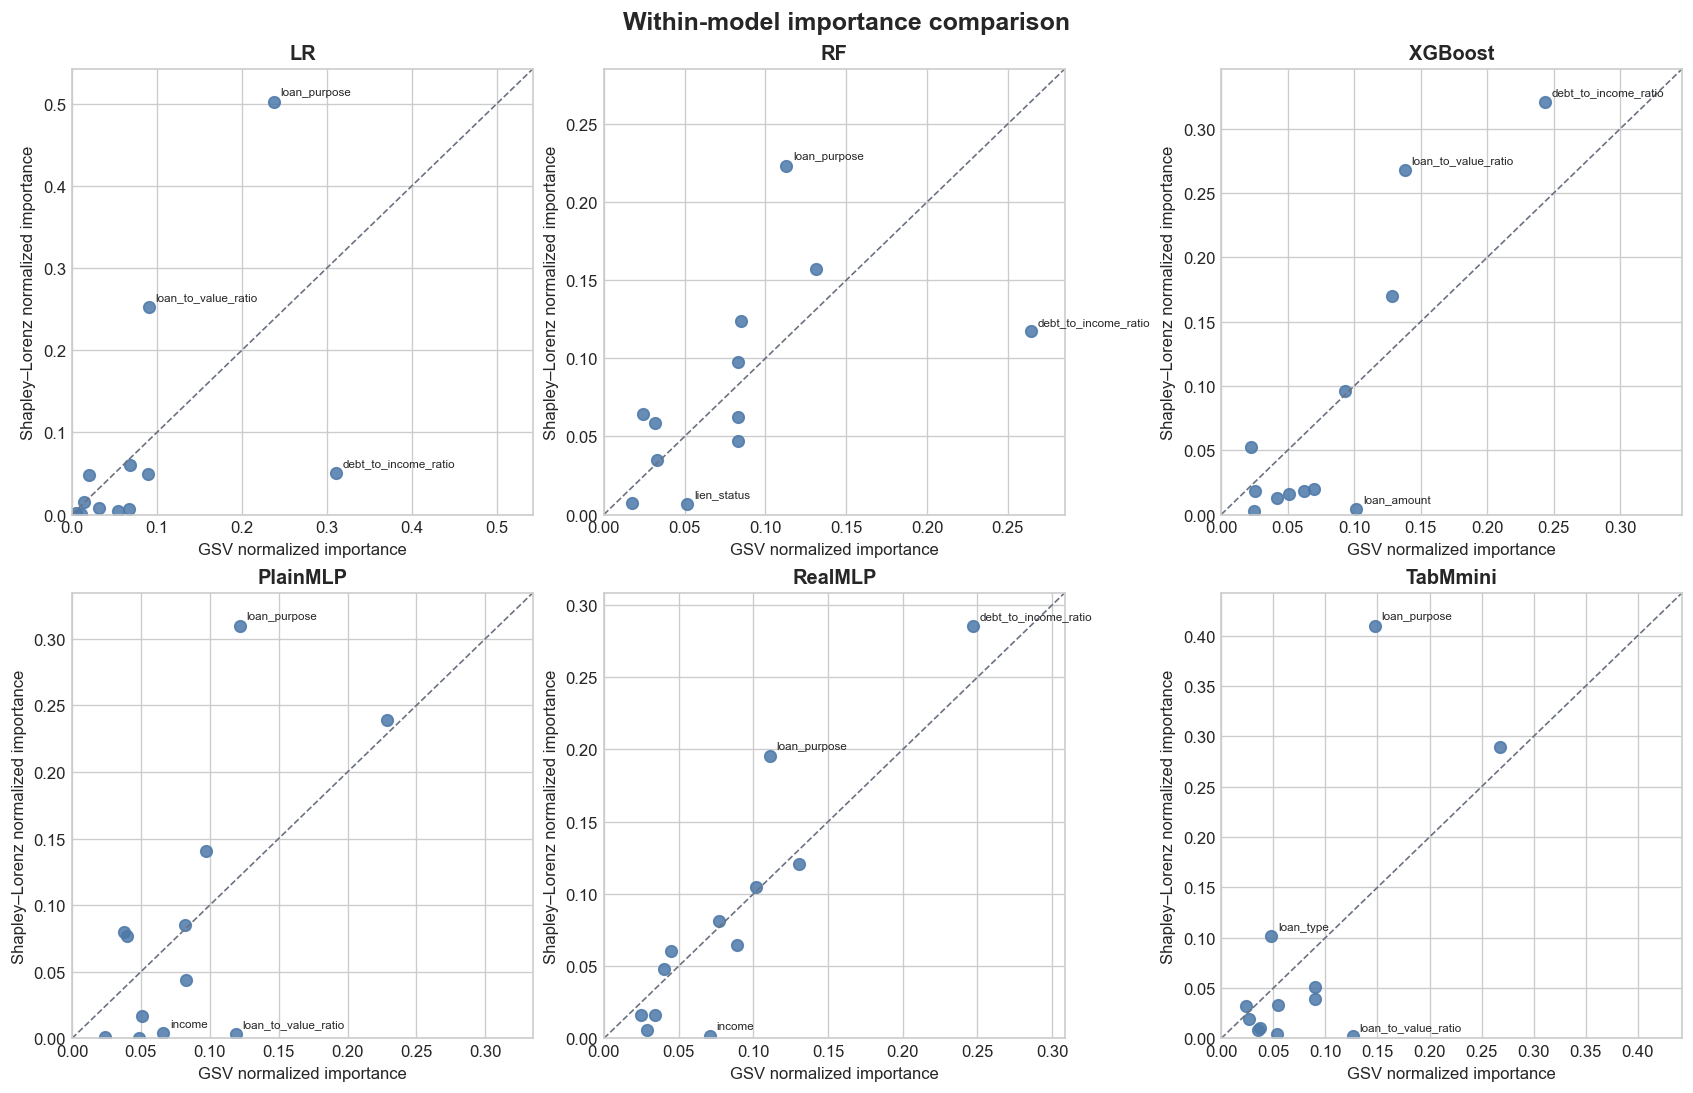

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(14, 9), constrained_layout=True)
for ax, model in zip(axes.flat, MODEL_ORDER):
    block = importance.loc[importance["model_key"].eq(model)].pivot(index="player_key", columns="method", values="normalized_importance")
    ax.scatter(block["gsv"], block["shapley_lorenz"], s=48, color="#4C78A8", alpha=0.85)
    limit = max(float(block.to_numpy().max()) * 1.08, 0.05)
    ax.plot([0, limit], [0, limit], linestyle="--", color="#6B7280", linewidth=1)
    largest_gaps = (block["gsv"] - block["shapley_lorenz"]).abs().nlargest(3).index
    for player in largest_gaps:
        ax.annotate(player, (block.loc[player, "gsv"], block.loc[player, "shapley_lorenz"]), xytext=(4, 4), textcoords="offset points", fontsize=7)
    ax.set(xlim=(0, limit), ylim=(0, limit), title=MODEL_LABELS[model], xlabel="GSV normalized importance", ylabel="Shapley–Lorenz normalized importance")
fig.suptitle("Within-model importance comparison", fontsize=15, fontweight="bold")
plt.show()

## 3. Within-model agreement with 95% bootstrap intervals

Each interval uses the saved 1,000-replicate cache-only bootstrap. The notebook reads the stored estimates and intervals; it does not resample or recompute them.

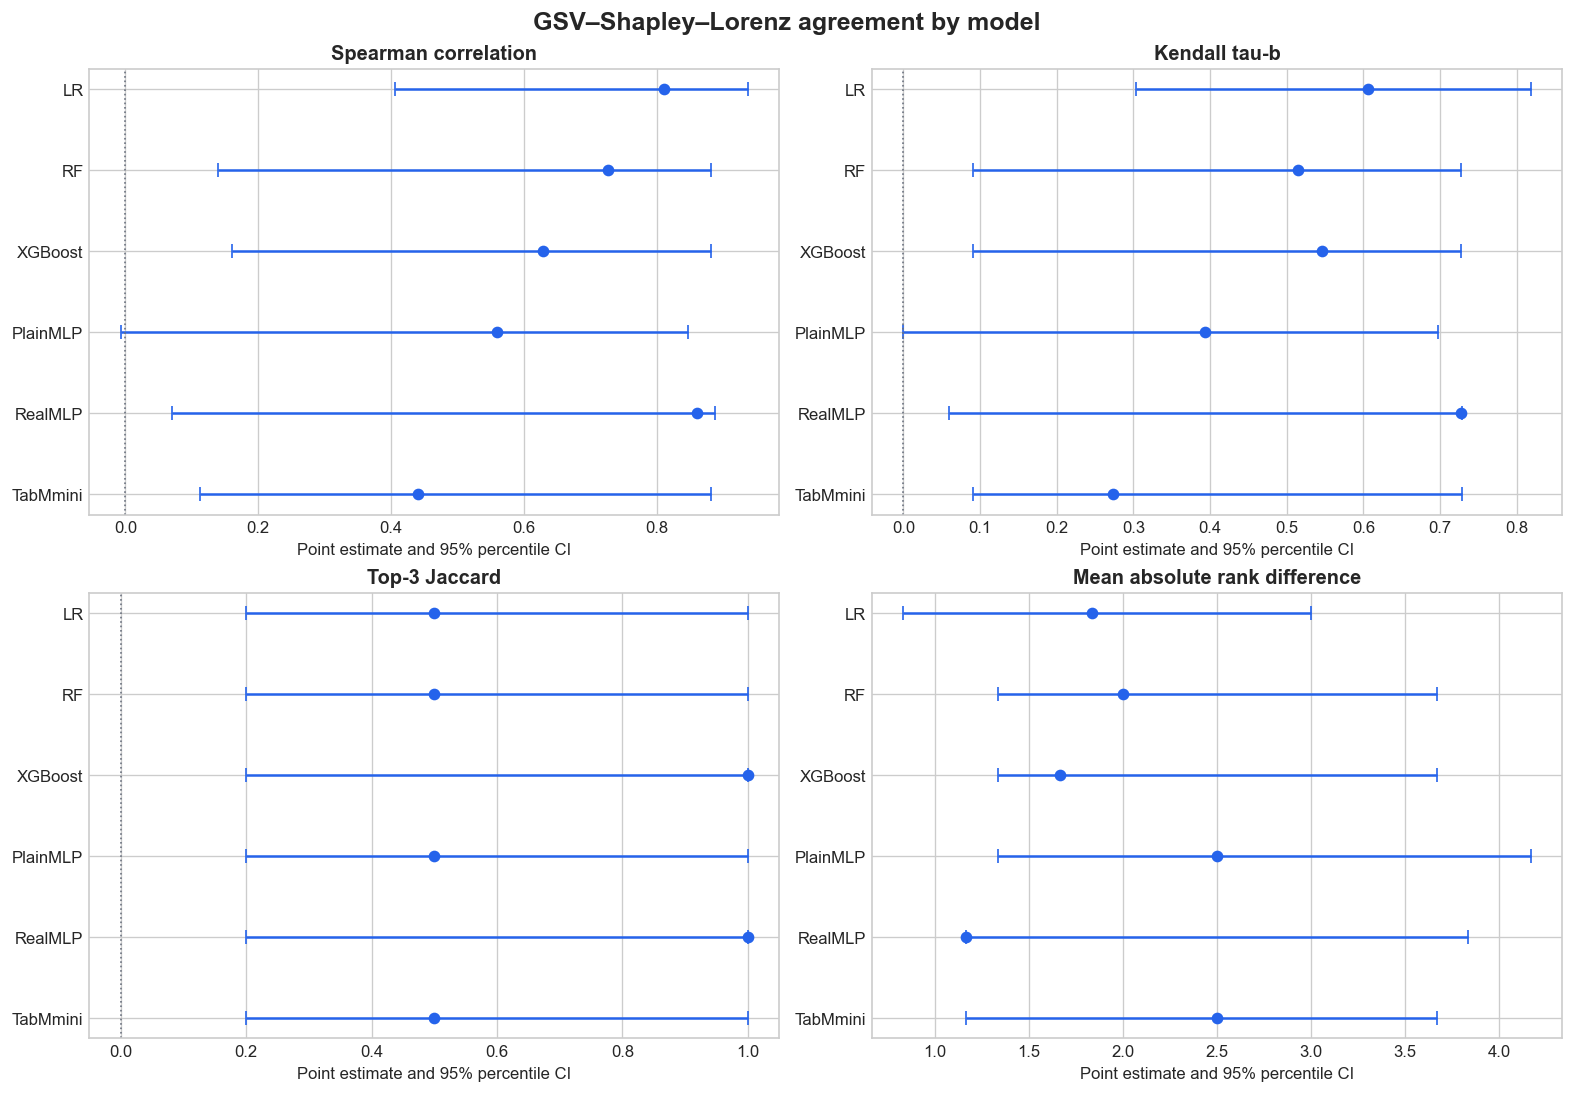

In [4]:
metric_specs = [
    ("spearman", "Spearman correlation"),
    ("kendall_tau_b", "Kendall tau-b"),
    ("top_k_jaccard", "Top-3 Jaccard"),
    ("mean_absolute_rank_difference", "Mean absolute rank difference"),
]
fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
for ax, (metric, title) in zip(axes.flat, metric_specs):
    block = bootstrap.loc[bootstrap["metric"].eq(metric)].set_index("model_key").loc[MODEL_ORDER].reset_index()
    y = np.arange(len(block))
    lower = block["point_estimate"] - block["ci_lower"]
    upper = block["ci_upper"] - block["point_estimate"]
    ax.errorbar(block["point_estimate"], y, xerr=np.vstack([lower, upper]), fmt="o", capsize=4, color="#2563EB")
    ax.set_yticks(y, [MODEL_LABELS[m] for m in block["model_key"]])
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel("Point estimate and 95% percentile CI")
    if metric != "mean_absolute_rank_difference":
        ax.axvline(0, color="#6B7280", linewidth=1, linestyle=":")
fig.suptitle("GSV–Shapley–Lorenz agreement by model", fontsize=15, fontweight="bold")
plt.show()

## 4. Cross-model descriptive stability

Heatmaps compare feature-importance rankings between model pairs separately for each explanation method. These are descriptive stability summaries, not model-performance comparisons.

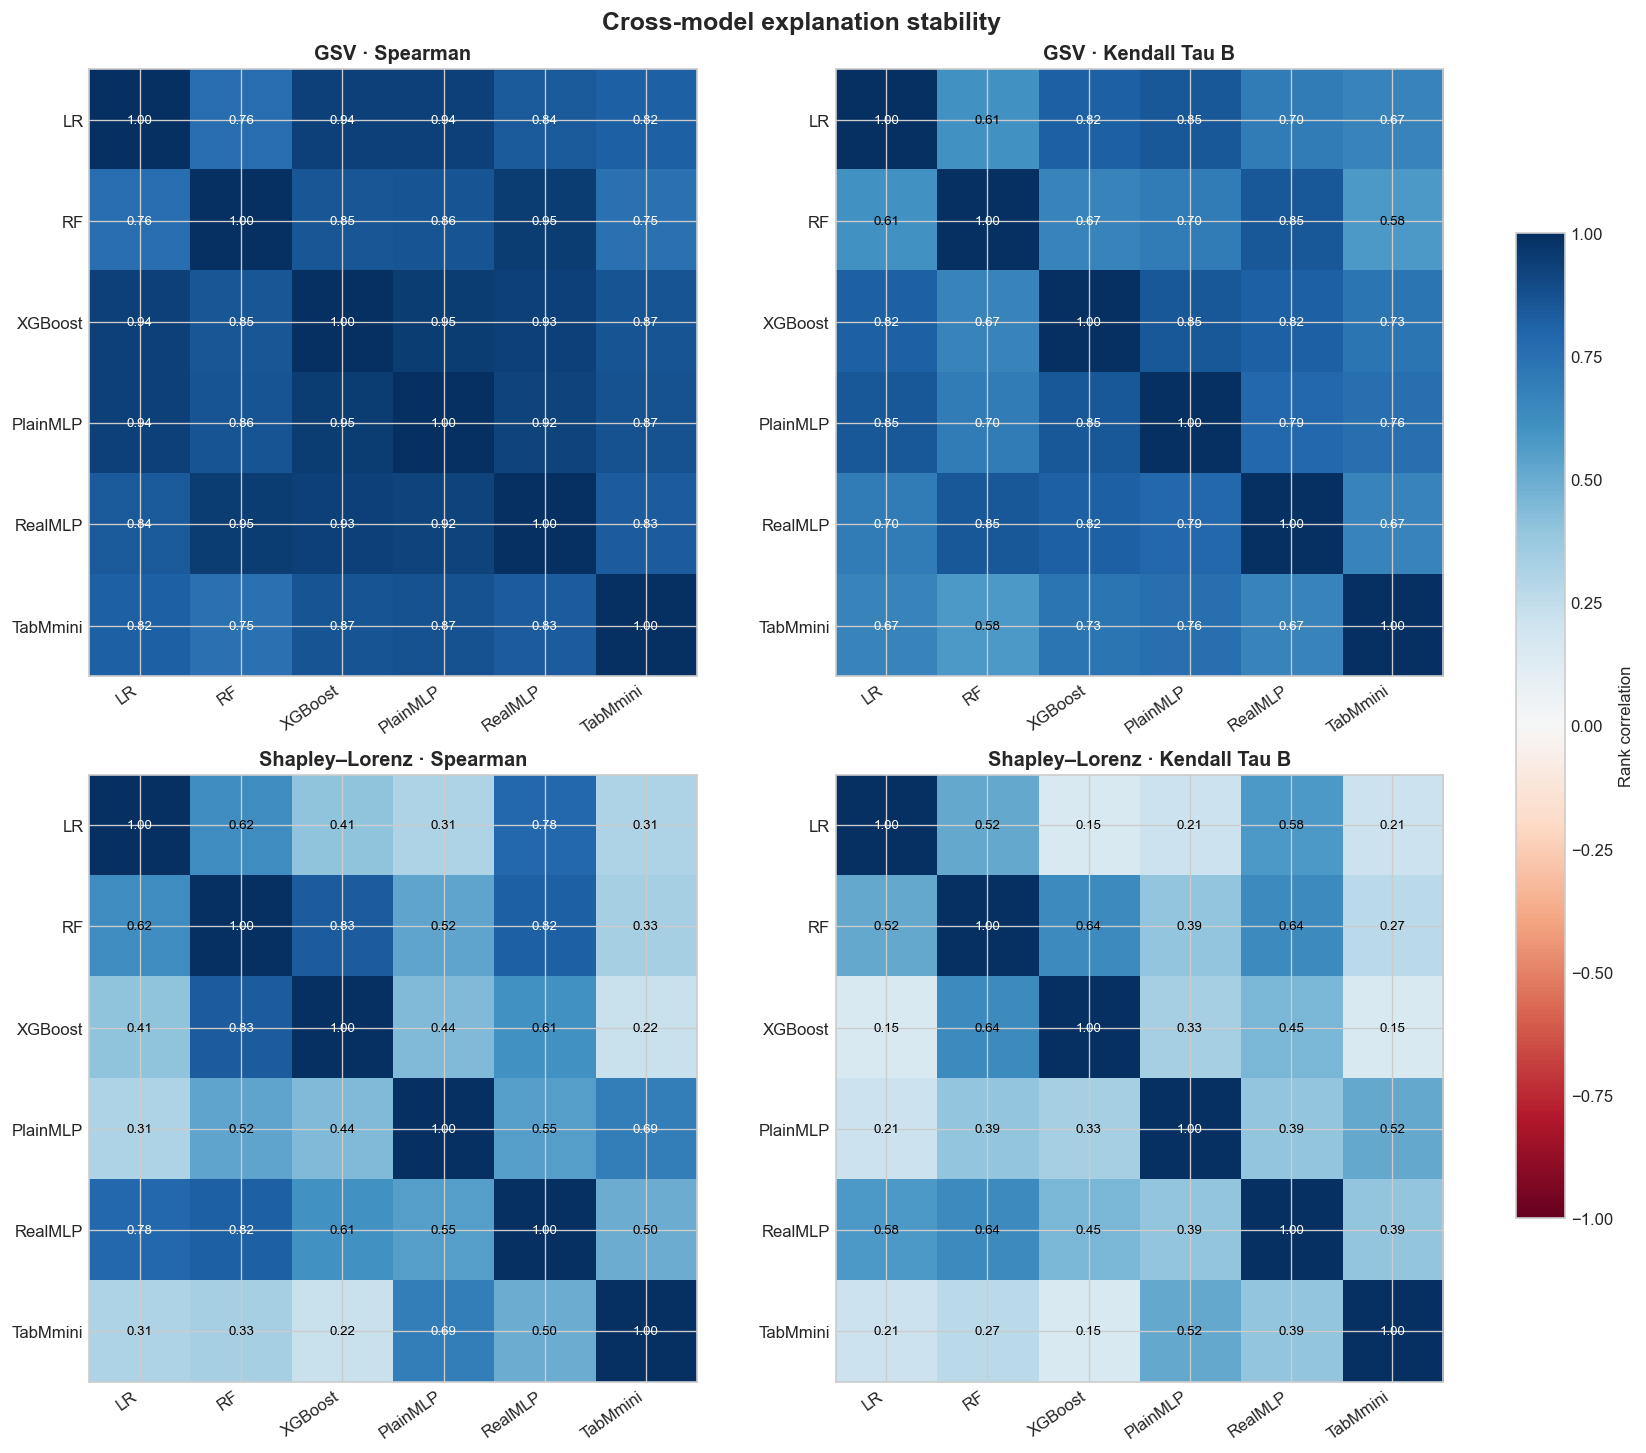

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12), constrained_layout=True)
for row, method in enumerate(["gsv", "shapley_lorenz"]):
    for col, metric in enumerate(["spearman", "kendall_tau_b"]):
        ax = axes[row, col]
        matrix = pd.DataFrame(np.eye(len(MODEL_ORDER)), index=MODEL_ORDER, columns=MODEL_ORDER)
        block = cross_model.loc[cross_model["method"].eq(method) & cross_model["metric"].eq(metric)]
        for item in block.itertuples(index=False):
            matrix.loc[item.left_model_key, item.right_model_key] = item.value
            matrix.loc[item.right_model_key, item.left_model_key] = item.value
        image = ax.imshow(matrix.to_numpy(), vmin=-1, vmax=1, cmap="RdBu")
        ax.set_xticks(range(6), [MODEL_LABELS[m] for m in MODEL_ORDER], rotation=35, ha="right")
        ax.set_yticks(range(6), [MODEL_LABELS[m] for m in MODEL_ORDER])
        for i in range(6):
            for j in range(6):
                ax.text(j, i, f"{matrix.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(matrix.iloc[i, j]) > 0.65 else "black")
        ax.set_title(f"{METHOD_LABELS[method]} · {metric.replace('_', ' ').title()}")
fig.colorbar(image, ax=axes, shrink=0.75, label="Rank correlation")
fig.suptitle("Cross-model explanation stability", fontsize=15, fontweight="bold")
plt.show()

## 5. Runtime and bootstrap validity

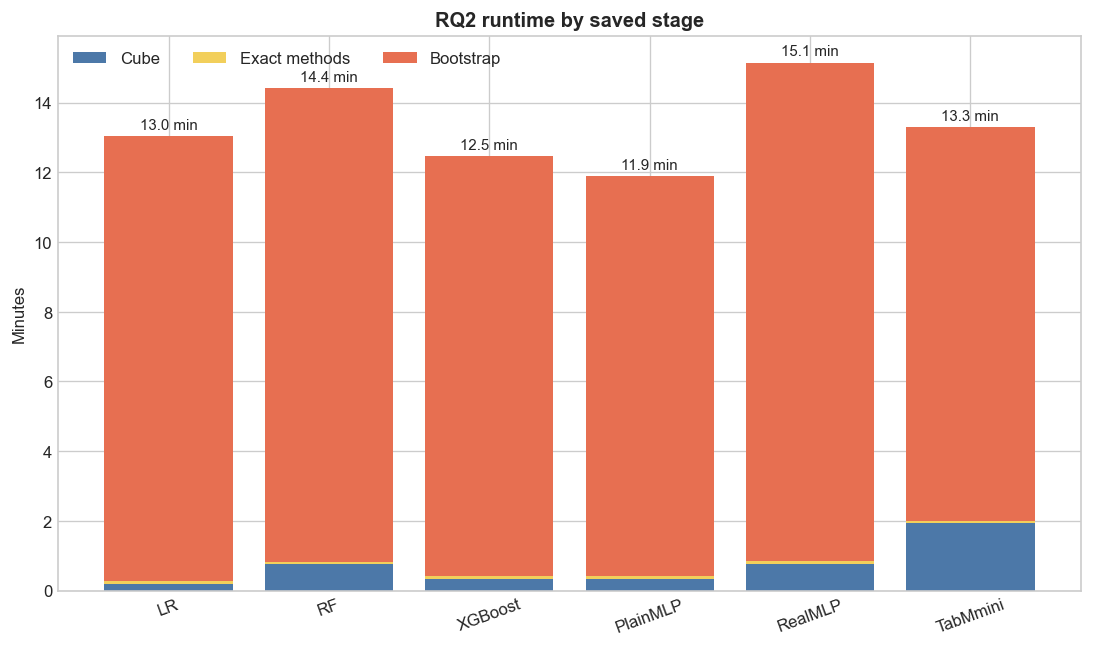

model,metric,valid_replicates,invalid_replicates,ci_available
LR,spearman,1000,0,True
LR,kendall_tau_b,1000,0,True
LR,top_k_jaccard,1000,0,True
LR,mean_absolute_rank_difference,1000,0,True
RF,spearman,1000,0,True
RF,kendall_tau_b,1000,0,True
RF,top_k_jaccard,1000,0,True
RF,mean_absolute_rank_difference,1000,0,True
XGBoost,spearman,1000,0,True
XGBoost,kendall_tau_b,1000,0,True


✅ **Bootstrap validity:** all 24 model–metric rows have 1,000 valid and 0 invalid replicates; all reported CIs are available.

In [6]:
runtime_plot = runtime.set_index("model_key").loc[MODEL_ORDER].copy()
components = ["cube_seconds", "method_seconds", "bootstrap_seconds"]
component_labels = ["Cube", "Exact methods", "Bootstrap"]
fig, ax = plt.subplots(figsize=(11, 6))
bottom = np.zeros(len(runtime_plot))
for column, label, color in zip(components, component_labels, ["#4C78A8", "#F2CF5B", "#E76F51"]):
    values = runtime_plot[column].to_numpy() / 60
    ax.bar([MODEL_LABELS[m] for m in MODEL_ORDER], values, bottom=bottom, label=label, color=color)
    bottom += values
for index, total in enumerate(runtime_plot["total_seconds"] / 60):
    ax.text(index, total + 0.2, f"{total:.1f} min", ha="center", fontsize=9)
ax.set_ylabel("Minutes")
ax.set_title("RQ2 runtime by saved stage")
ax.legend(ncol=3, frameon=False)
plt.xticks(rotation=20)
plt.show()

bootstrap_validity = bootstrap[["model_key", "metric", "valid_replicates", "invalid_replicates", "ci_available"]].copy()
bootstrap_validity["model"] = bootstrap_validity["model_key"].map(MODEL_LABELS)
display(bootstrap_validity[["model", "metric", "valid_replicates", "invalid_replicates", "ci_available"]].style.hide(axis="index"))
invalid_total = int(bootstrap_validity["invalid_replicates"].sum())
if invalid_total:
    display(Markdown(f"⚠️ **Bootstrap warning:** {invalid_total} invalid replicates were recorded. Review per-metric counts before interpretation."))
else:
    display(Markdown("✅ **Bootstrap validity:** all 24 model–metric rows have 1,000 valid and 0 invalid replicates; all reported CIs are available."))

## 6. Descriptive result tables and interpretation boundary

In [7]:
agreement_table = bootstrap.pivot(index="model_key", columns="metric", values="point_estimate").loc[MODEL_ORDER]
agreement_table.index = [MODEL_LABELS[m] for m in agreement_table.index]
agreement_table.index.name = "model"
display(agreement_table.style.format("{:.3f}"))

stability_range = cross_model.groupby(["method", "metric"])["value"].agg(["min", "median", "max"]).reset_index()
stability_range["method"] = stability_range["method"].map(METHOD_LABELS)
display(stability_range.style.hide(axis="index").format({"min": "{:.3f}", "median": "{:.3f}", "max": "{:.3f}"}))

display(Markdown("**Interpretation boundary.** Agreement indicates how similarly GSV and Shapley–Lorenz rank importance within a frozen model. Cross-model stability indicates how similar rankings are across frozen models for one method. Neither quantity validates an explanation as true, causal, fair, or legally compliant."))

metric,kendall_tau_b,mean_absolute_rank_difference,spearman,top_k_jaccard
model,,,,
LR,0.606,1.833,0.811,0.500
RF,0.515,2.000,0.727,0.500
XGBoost,0.545,1.667,0.629,1.000
PlainMLP,0.394,2.500,0.559,0.500
RealMLP,0.727,1.167,0.860,1.000
TabMmini,0.273,2.500,0.441,0.500


method,metric,min,median,max
GSV,kendall_tau_b,0.576,0.727,0.848
GSV,spearman,0.748,0.867,0.951
Shapley–Lorenz,kendall_tau_b,0.152,0.394,0.636
Shapley–Lorenz,spearman,0.224,0.524,0.832


**Interpretation boundary.** Agreement indicates how similarly GSV and Shapley–Lorenz rank importance within a frozen model. Cross-model stability indicates how similar rankings are across frozen models for one method. Neither quantity validates an explanation as true, causal, fair, or legally compliant.

## 7. Player-rank heatmaps across six models

Ranks are shown separately for GSV and Shapley–Lorenz. Rank 1 denotes the highest normalized importance within a model; the heatmaps compare observed ranking patterns and do not identify a correct explanation.

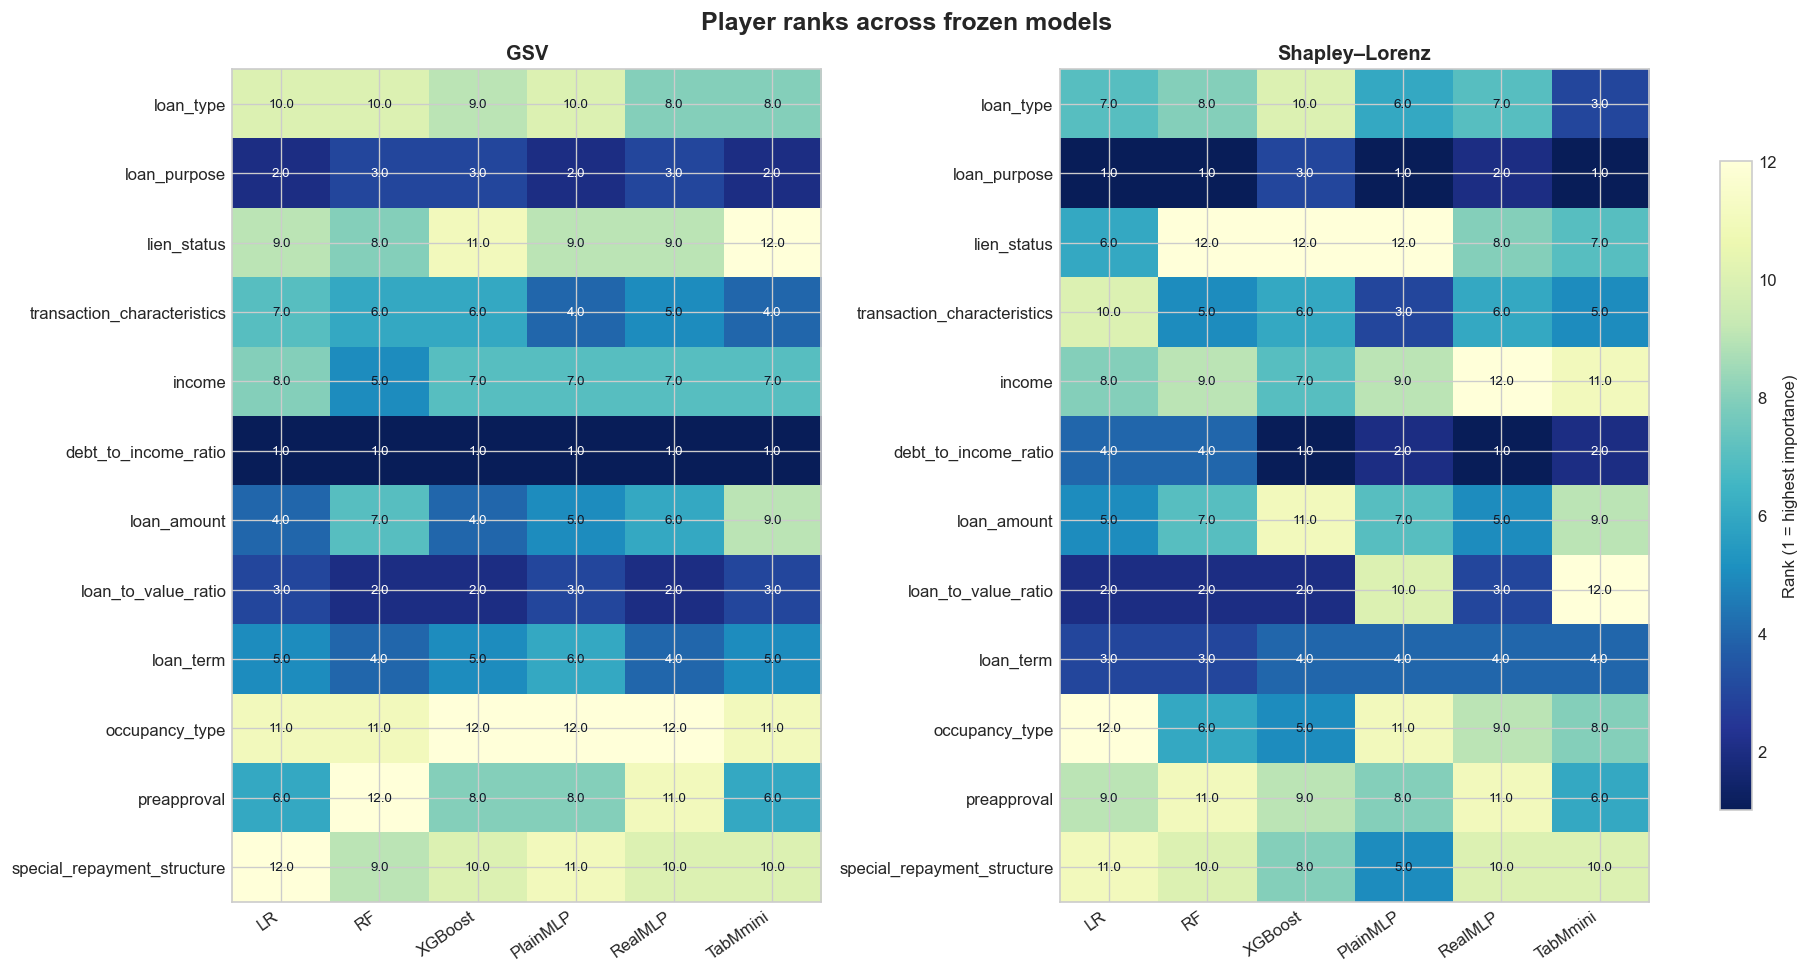

In [8]:
PLAYER_ORDER = (
    importance[["player_index", "player_key"]]
    .drop_duplicates()
    .sort_values("player_index")["player_key"]
    .tolist()
)
MODEL_COLORS = {
    "lr": "#4C78A8", "rf": "#F58518", "xgboost": "#54A24B",
    "plain_mlp": "#E45756", "realmlp": "#B279A2", "tabmmini": "#72B7B2",
}

fig, axes = plt.subplots(1, 2, figsize=(15, 8), constrained_layout=True)
for ax, method in zip(axes, ["gsv", "shapley_lorenz"]):
    rank_matrix = (
        importance.loc[importance["method"].eq(method)]
        .pivot(index="player_key", columns="model_key", values="rank")
        .loc[PLAYER_ORDER, MODEL_ORDER]
    )
    image = ax.imshow(rank_matrix.to_numpy(), vmin=1, vmax=len(PLAYER_ORDER), cmap="YlGnBu_r", aspect="auto")
    ax.set_xticks(range(len(MODEL_ORDER)), [MODEL_LABELS[m] for m in MODEL_ORDER], rotation=35, ha="right")
    ax.set_yticks(range(len(PLAYER_ORDER)), PLAYER_ORDER)
    for row in range(len(PLAYER_ORDER)):
        for col in range(len(MODEL_ORDER)):
            value = rank_matrix.iloc[row, col]
            ax.text(col, row, f"{value:.1f}", ha="center", va="center", fontsize=8, color="white" if value <= 4 else "#111827")
    ax.set_title(METHOD_LABELS[method])
fig.colorbar(image, ax=axes, shrink=0.78, label="Rank (1 = highest importance)")
fig.suptitle("Player ranks across frozen models", fontsize=15, fontweight="bold")
plt.show()

## 8. Normalized player importance across six models

The grouped horizontal bars retain player identity while comparing all six frozen models. GSV and Shapley–Lorenz remain in separate panels because each method is normalized independently.

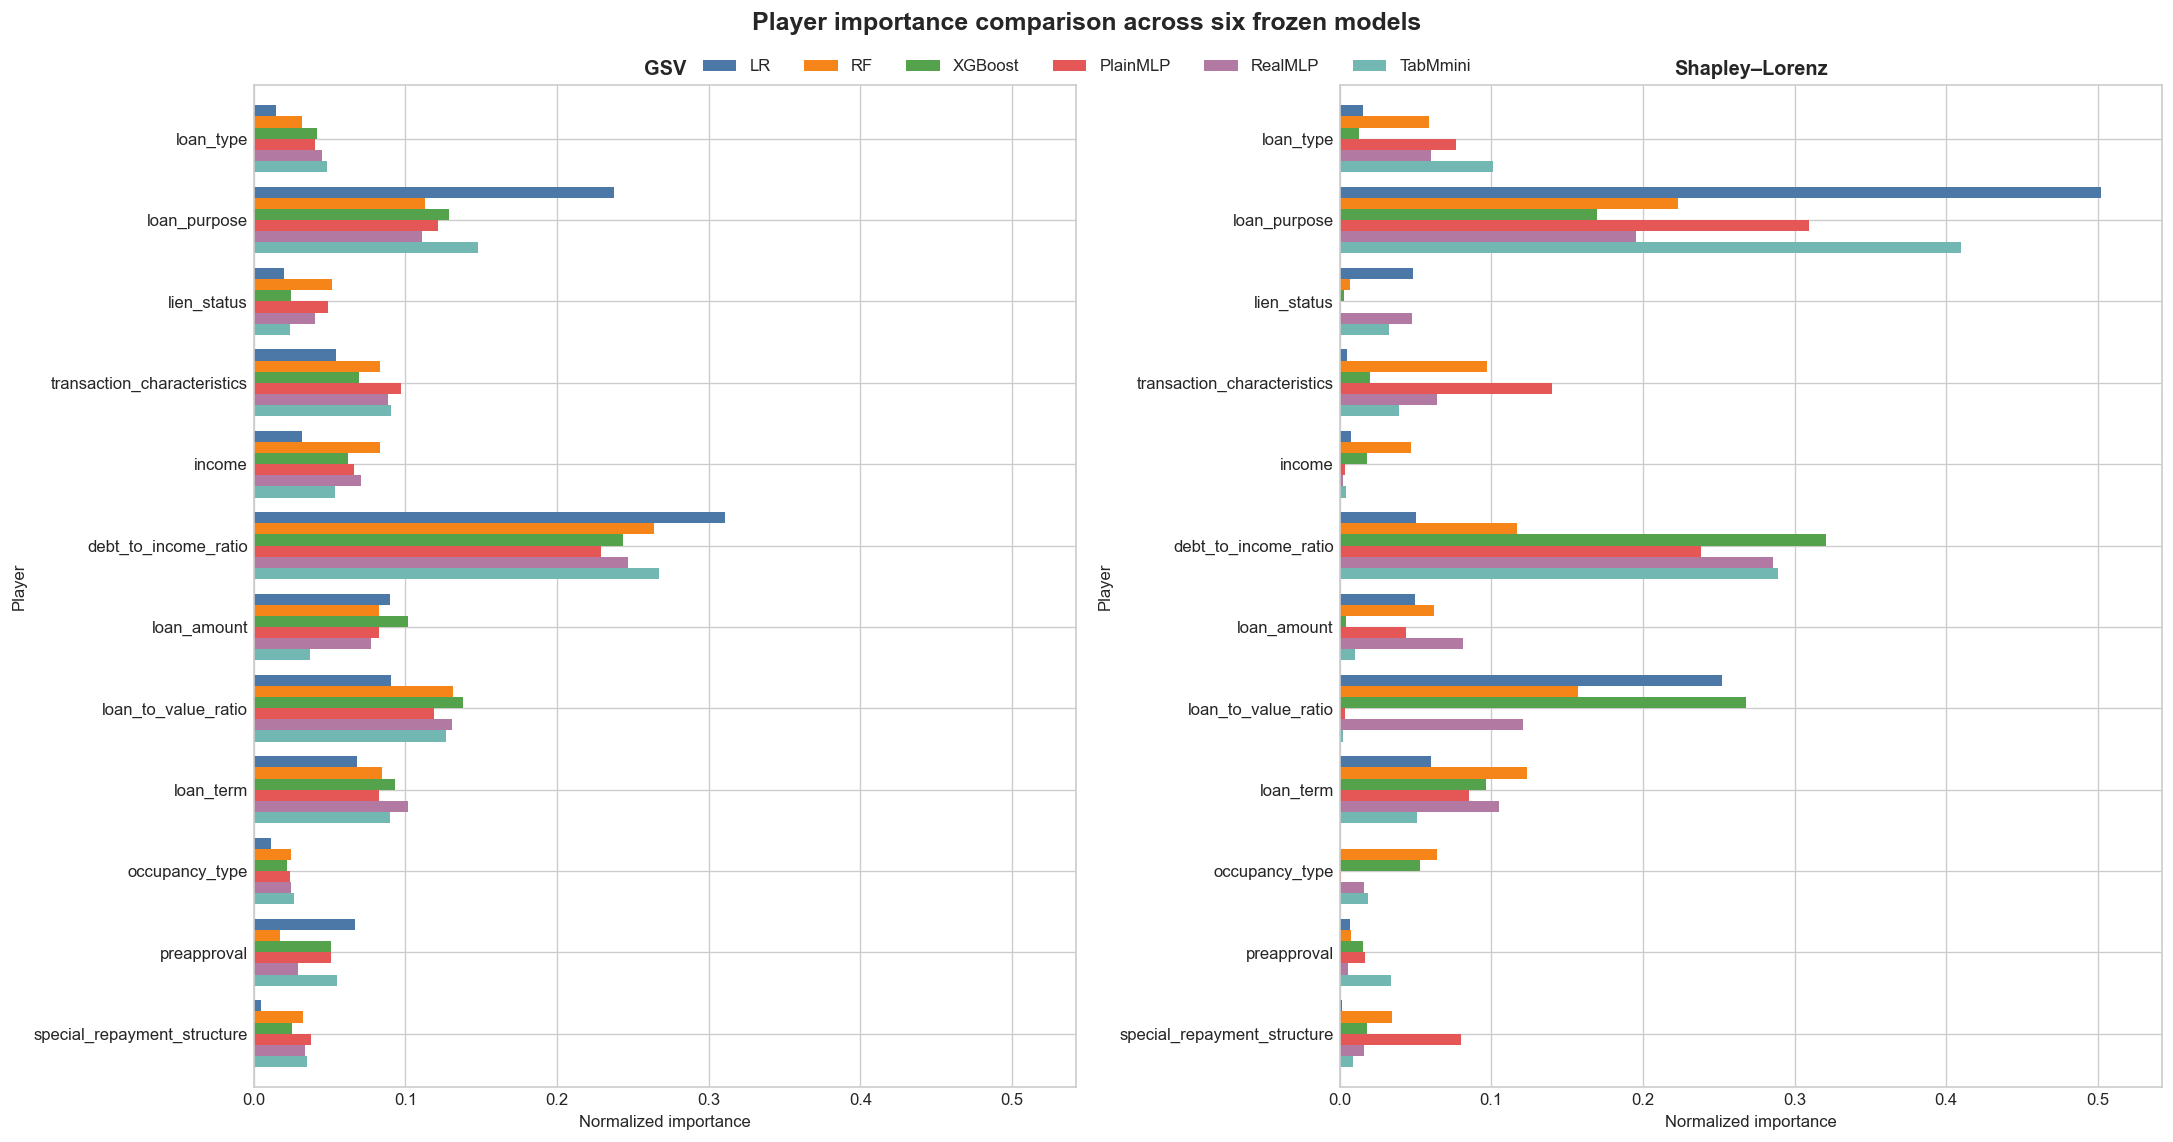

In [9]:
importance_limit = float(importance["normalized_importance"].max()) * 1.08
fig, axes = plt.subplots(1, 2, figsize=(18, 9), sharex=True, constrained_layout=True)
legend_handles = None
for ax, method in zip(axes, ["gsv", "shapley_lorenz"]):
    comparison = (
        importance.loc[importance["method"].eq(method)]
        .pivot(index="player_key", columns="model_key", values="normalized_importance")
        .loc[PLAYER_ORDER, MODEL_ORDER]
    )
    comparison.plot.barh(
        ax=ax, width=0.82, color=[MODEL_COLORS[m] for m in MODEL_ORDER], legend=True
    )
    handles, _ = ax.get_legend_handles_labels()
    legend_handles = handles
    ax.get_legend().remove()
    ax.invert_yaxis()
    ax.set_xlim(0, importance_limit)
    ax.set_xlabel("Normalized importance")
    ax.set_ylabel("Player")
    ax.set_title(METHOD_LABELS[method])
fig.legend(legend_handles, [MODEL_LABELS[m] for m in MODEL_ORDER], loc="upper center", bbox_to_anchor=(0.5, 1.01), ncol=6, frameon=False)
fig.suptitle("Player importance comparison across six frozen models", fontsize=15, fontweight="bold", y=1.04)
plt.show()

## 9. Within-model GSV–Shapley–Lorenz importance gaps

Each dumbbell joins the two saved normalized-importance values for one player. Longer segments indicate a larger method-specific difference for that frozen model, not superiority of either method.

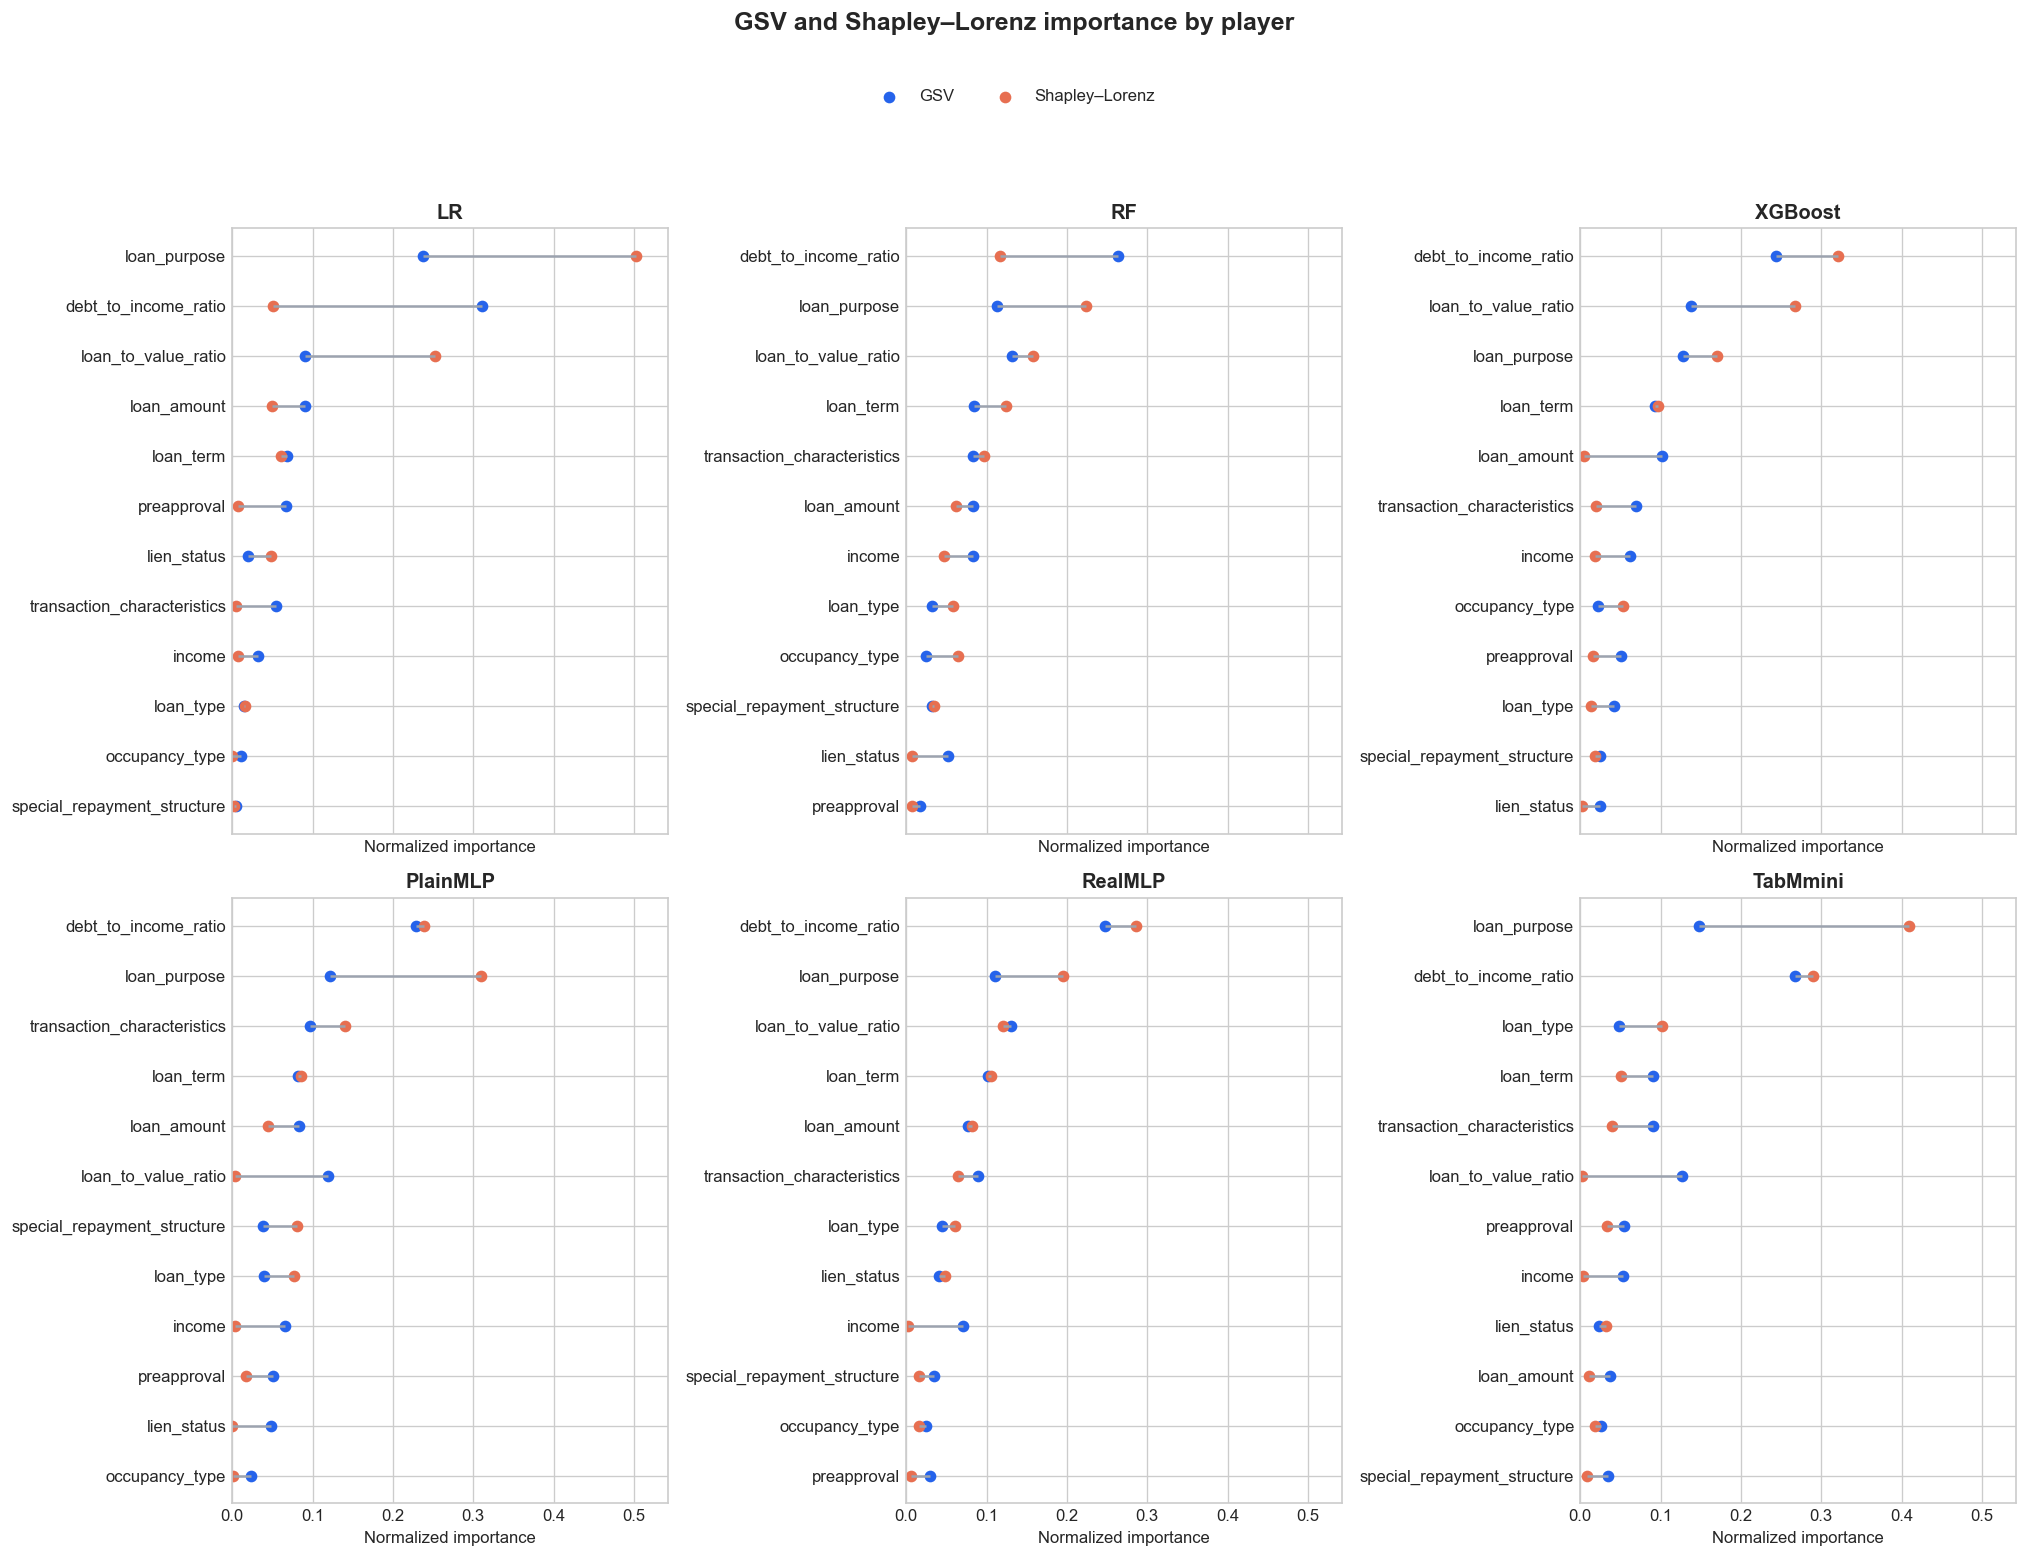

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(17, 13), sharex=True)
for ax, model in zip(axes.flat, MODEL_ORDER):
    gaps = (
        importance.loc[importance["model_key"].eq(model)]
        .pivot(index="player_key", columns="method", values="normalized_importance")
    )
    gaps["mean_importance"] = gaps[["gsv", "shapley_lorenz"]].mean(axis=1)
    gaps = gaps.sort_values("mean_importance", ascending=True)
    y = np.arange(len(gaps))
    ax.hlines(y, gaps["gsv"], gaps["shapley_lorenz"], color="#9CA3AF", linewidth=1.5)
    ax.scatter(gaps["gsv"], y, color=COLORS["gsv"], s=36, label=METHOD_LABELS["gsv"])
    ax.scatter(gaps["shapley_lorenz"], y, color=COLORS["shapley_lorenz"], s=36, label=METHOD_LABELS["shapley_lorenz"])
    ax.set_yticks(y, gaps.index)
    ax.set_xlim(0, importance_limit)
    ax.set_xlabel("Normalized importance")
    ax.set_title(MODEL_LABELS[model])
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.955), ncol=2, frameon=False)
fig.suptitle("GSV and Shapley–Lorenz importance by player", fontsize=15, fontweight="bold", y=0.995)
fig.tight_layout(rect=[0, 0, 1, 0.91])
plt.show()

## 10. Player-rank dispersion across models

The horizontal interval spans the minimum to maximum observed rank across the six models, and the point marks the median rank. A shorter interval indicates greater descriptive rank stability within that method.

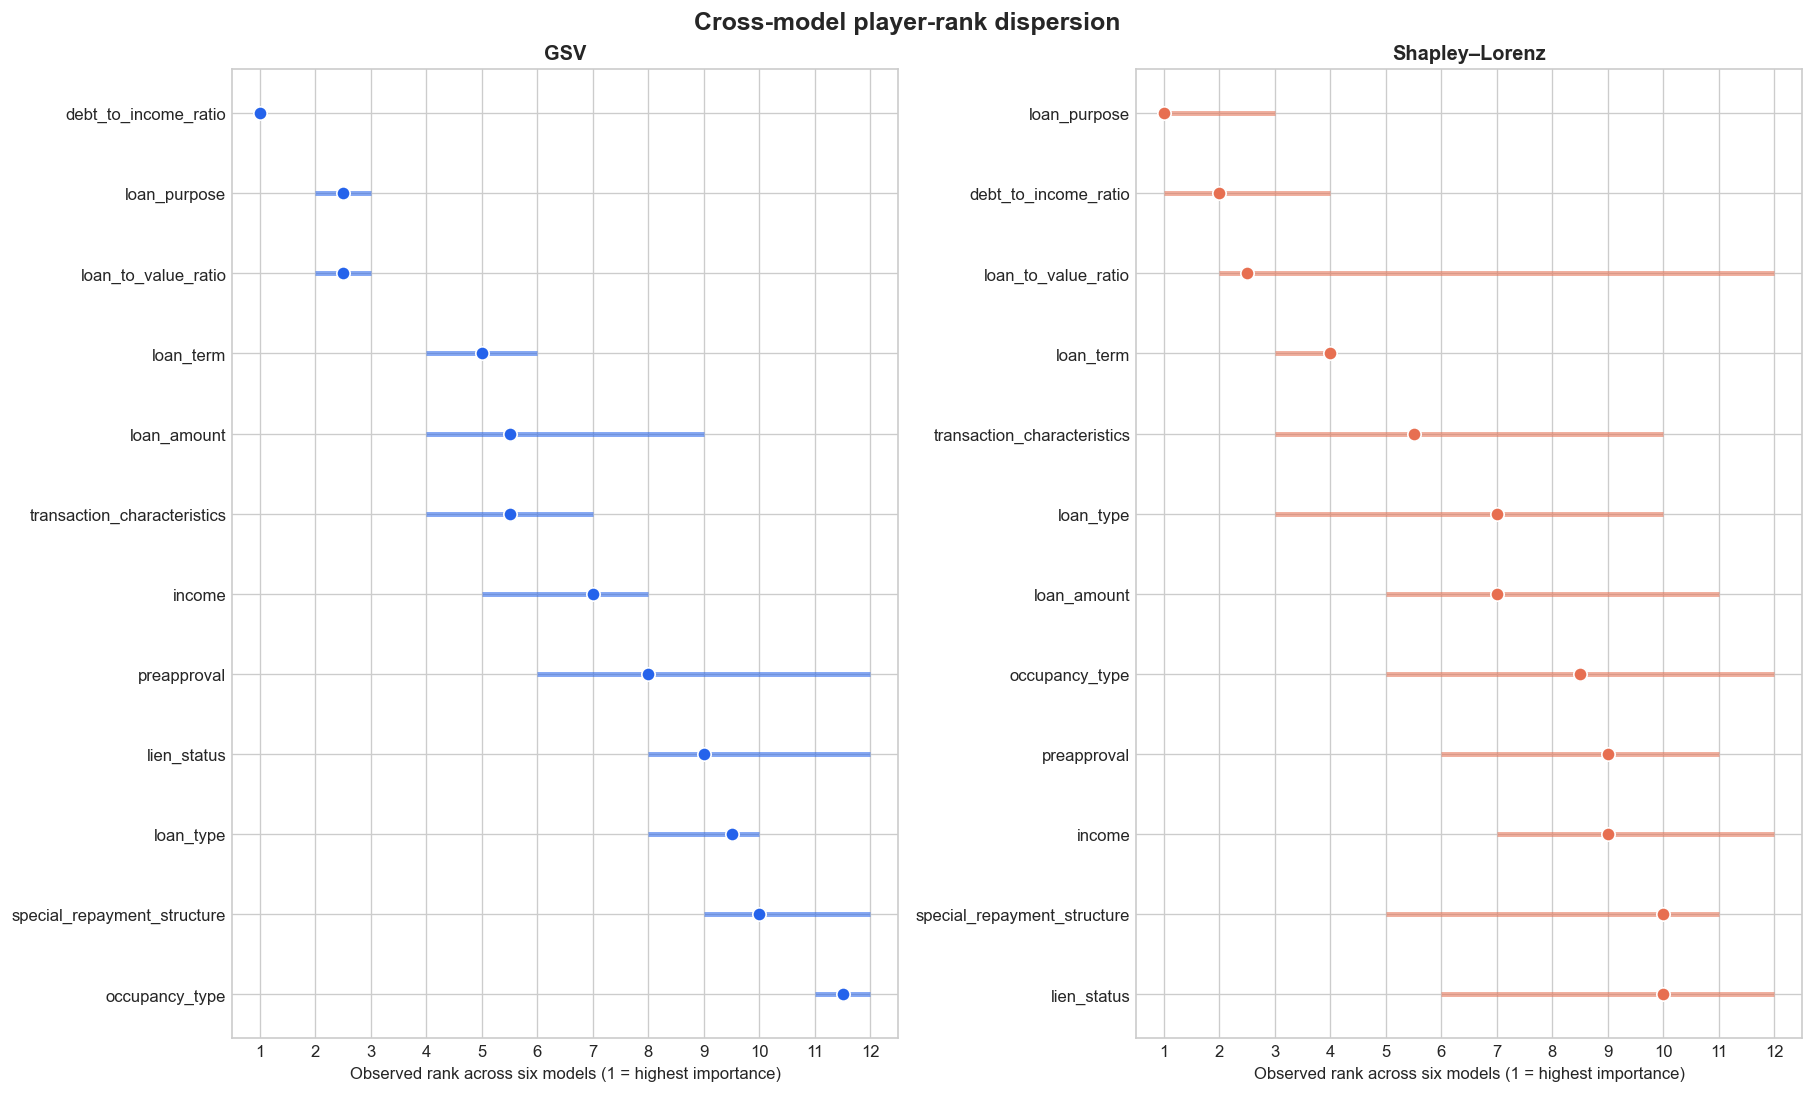

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 9), sharex=True, constrained_layout=True)
for ax, method in zip(axes, ["gsv", "shapley_lorenz"]):
    dispersion = (
        importance.loc[importance["method"].eq(method)]
        .groupby("player_key")["rank"]
        .agg(rank_min="min", rank_median="median", rank_max="max")
        .sort_values(["rank_median", "rank_min"], ascending=True)
    )
    y = np.arange(len(dispersion))
    ax.hlines(y, dispersion["rank_min"], dispersion["rank_max"], color=COLORS[method], linewidth=3, alpha=0.55)
    ax.scatter(dispersion["rank_median"], y, color=COLORS[method], edgecolor="white", s=64, zorder=3)
    ax.set_yticks(y, dispersion.index)
    ax.invert_yaxis()
    ax.set_xticks(range(1, len(PLAYER_ORDER) + 1))
    ax.set_xlim(0.5, len(PLAYER_ORDER) + 0.5)
    ax.set_xlabel("Observed rank across six models (1 = highest importance)")
    ax.set_title(METHOD_LABELS[method])
fig.suptitle("Cross-model player-rank dispersion", fontsize=15, fontweight="bold")
plt.show()

## 11. Research summary panel

This panel is generated only from the accepted production tables. It summarizes observed agreement and stability without treating either explanation method as ground truth.

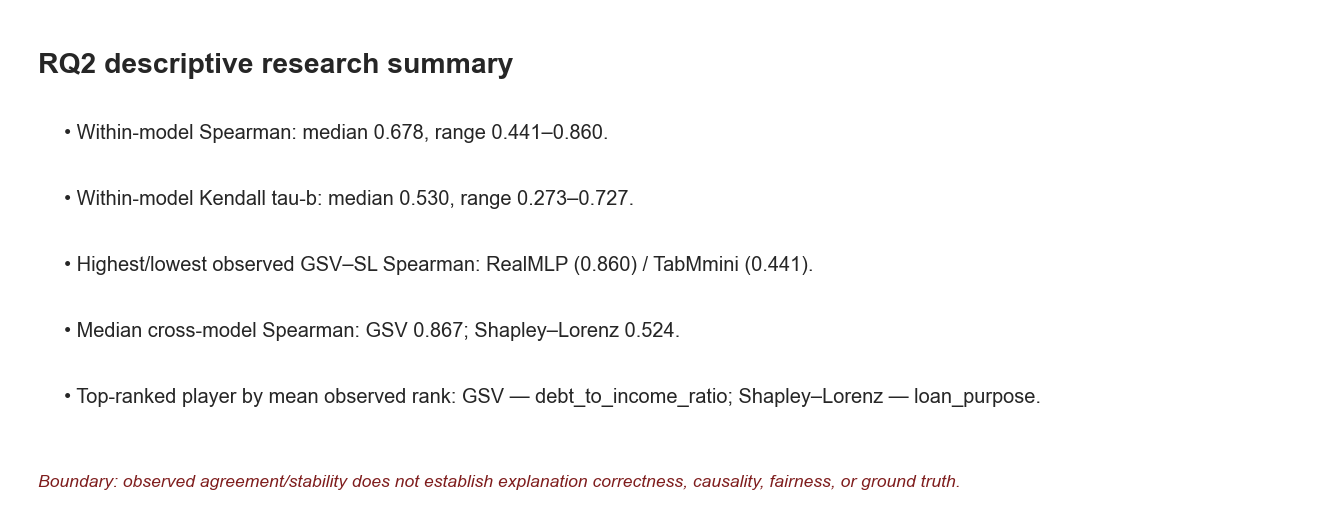

In [12]:
within_spearman = bootstrap.loc[bootstrap["metric"].eq("spearman")].set_index("model_key")["point_estimate"].loc[MODEL_ORDER]
within_kendall = bootstrap.loc[bootstrap["metric"].eq("kendall_tau_b")].set_index("model_key")["point_estimate"].loc[MODEL_ORDER]
cross_spearman = cross_model.loc[cross_model["metric"].eq("spearman")].groupby("method")["value"].median()
mean_ranks = importance.groupby(["method", "player_key"])["rank"].mean()
gsv_leader = mean_ranks.loc["gsv"].idxmin()
sl_leader = mean_ranks.loc["shapley_lorenz"].idxmin()
best_model = within_spearman.idxmax()
lowest_model = within_spearman.idxmin()

summary_lines = [
    f"Within-model Spearman: median {within_spearman.median():.3f}, range {within_spearman.min():.3f}–{within_spearman.max():.3f}.",
    f"Within-model Kendall tau-b: median {within_kendall.median():.3f}, range {within_kendall.min():.3f}–{within_kendall.max():.3f}.",
    f"Highest/lowest observed GSV–SL Spearman: {MODEL_LABELS[best_model]} ({within_spearman[best_model]:.3f}) / {MODEL_LABELS[lowest_model]} ({within_spearman[lowest_model]:.3f}).",
    f"Median cross-model Spearman: GSV {cross_spearman['gsv']:.3f}; Shapley–Lorenz {cross_spearman['shapley_lorenz']:.3f}.",
    f"Top-ranked player by mean observed rank: GSV — {gsv_leader}; Shapley–Lorenz — {sl_leader}.",
]
fig, ax = plt.subplots(figsize=(14, 5.5))
ax.axis("off")
ax.text(0.02, 0.92, "RQ2 descriptive research summary", fontsize=17, fontweight="bold", va="top")
for index, line in enumerate(summary_lines):
    ax.text(0.04, 0.78 - index * 0.13, f"• {line}", fontsize=12, va="top")
ax.text(
    0.02, 0.06,
    "Boundary: observed agreement/stability does not establish explanation correctness, causality, fairness, or ground truth.",
    fontsize=10.5, color="#7F1D1D", style="italic", va="bottom",
)
plt.show()